In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

Saving 134144297073983372.jpg to 134144297073983372.jpg


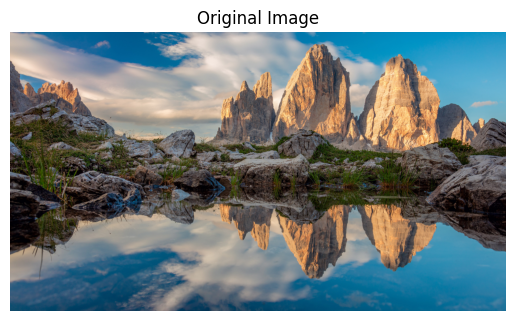

In [2]:
uploaded = files.upload()

image_path = next(iter(uploaded))
image = cv2.imread(image_path)

if image is None:
    raise ValueError("Unable to load image. Please upload a valid image.")

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.imshow(image_rgb)
plt.title("Original Image")
plt.axis("off")
plt.show()

In [3]:
hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

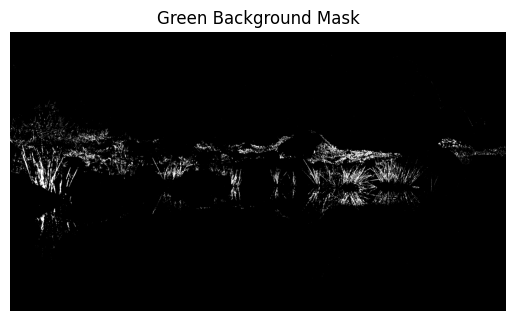

In [4]:
lower_green = np.array([35, 50, 50])
upper_green = np.array([85, 255, 255])

mask = cv2.inRange(hsv, lower_green, upper_green)

plt.imshow(mask, cmap="gray")
plt.title("Green Background Mask")
plt.axis("off")
plt.show()

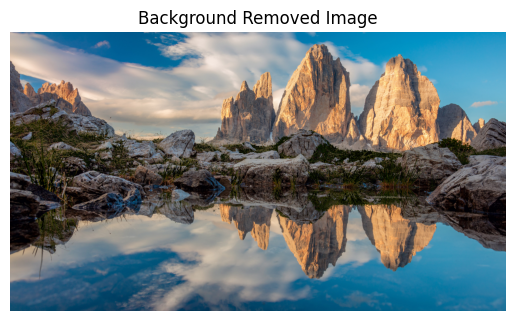

In [5]:
foreground_mask = cv2.bitwise_not(mask)

result = cv2.bitwise_and(
    image,
    image,
    mask=foreground_mask
)

result_rgb = cv2.cvtColor(result, cv2.COLOR_BGR2RGB)

plt.imshow(result_rgb)
plt.title("Background Removed Image")
plt.axis("off")
plt.show()

In [6]:
output_path = "background_subtraction_output.jpg"

cv2.imwrite(output_path, result)

files.download(output_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>